# Look at results from metab x antibiotic use regressions on clinical chemistries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

import re
import ast
from rich.progress import track
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import statsmodels.robust.norms as norms

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
# Now you can import your file
from regression_functions import *

## Read in raw data for plotting

In [2]:
# ---- Read + merge ------------
labs_clean = pd.read_csv("../data/clincal_chems_abx_users_clean.csv", dtype={'public_client_id': str})
metabolites_merged = pd.read_csv("../data/metabolites_merged_used_for_regressions.csv", dtype={'public_client_id': str})

# Grab vendor
quest = labs_clean[labs_clean['vendor'] == 'Quest']
labcorp = labs_clean[labs_clean['vendor'] == 'LCA']

# Prepare labs for merge
lab_features = labs_clean.columns[31:].tolist()
cols = lab_features + ['vendor']
labs_clean.set_index('public_client_id', inplace=True)
labs_for_merge = labs_clean[cols].reset_index()

# Merge and set year var
labs_mets = metabolites_merged.merge(labs_for_merge, on='public_client_id', how='left')
labs_mets['abx_year'] = labs_mets['abx_recency'].apply(lambda x: "none" if x == "none" else "past_year")

metabolite_features = metabolites_merged.columns[27:].tolist()
not_offered_quest = quest[lab_features].isna().all().index[quest[lab_features].isna().all()].tolist()
not_offered_labcorp = labcorp[lab_features].isna().all().index[labcorp[lab_features].isna().all()].tolist()
individual_vendors = not_offered_labcorp + not_offered_quest
shared_labs = list(set(lab_features) - set(individual_vendors))

## Read in results from interactions

In [3]:
interaction_results = pd.read_csv("../data/metabolite_abx_interactions_on_labs.csv")

In [4]:
sig_interactions = interaction_results[
(interaction_results['q_value'] < 0.1) & (interaction_results['q_value_global'] < 0.1)
].sort_values(by=['q_value_global','q_value'])

In [5]:
# sig_interactions

### Merge annotations

In [6]:
anns_snapshot = pd.read_csv("../data/metabolites_snapshot_updated.csv")
anns_snapshot = anns_snapshot.rename(columns={'feature':'metabolite'})

In [7]:
# Add annotations to the significant hits
sig_ints_anns = sig_interactions.merge(anns_snapshot, on='metabolite', how='left')
# sig_ints_anns.chemistry.value_counts()

In [8]:
lmplot_chems = sig_ints_anns.chemistry.value_counts()[sig_ints_anns.chemistry.value_counts() <= 3].index.tolist()
barbell_chems = sig_ints_anns.chemistry.value_counts()[sig_ints_anns.chemistry.value_counts() > 3].index.tolist()

lmplot_chems_df = sig_ints_anns[sig_ints_anns.chemistry.isin(lmplot_chems)]
barbell_chems_df = sig_ints_anns[sig_ints_anns.chemistry.isin(barbell_chems)]

lmplot_tuples = list(zip(lmplot_chems_df.chemistry, lmplot_chems_df.metabolite))
len(lmplot_tuples)

33

In [9]:
barbell_chems_df.chemistry.unique()

array(['TriglycerideHDLRatio', 'TRIGLYCERIDES', 'IL_6',
       'TOTALNEUTROPHILS', 'LYMPHOCYTES'], dtype=object)

In [10]:
covariates = ["sex", "age", "BMI_CALC", "meds_cholesterol",
              "meds_blood_sugar", "PC1", "PC2", "PC3", "PC4", "PC5",
              "centered_eGFR", "vendor"]

## Check if association relies on high leverage points

In [11]:
# metabolites = adi.get_snapshot("metabolomics_corrected").sort_values(by="days_in_program")

In [12]:
def interaction_influence(df, lab, metabolite, covars,
                          abx="abx_year"):
    """Refit one lab~abx*metabolite+covars model, return influence on the
    interaction term + a leverage-dropped refit for comparison."""
    d = df[[lab, abx, metabolite] + covars].dropna().copy()
    n = len(d)

    rhs = f"C({abx}) * {metabolite}" + ("" if not covars else " + " + " + ".join(covars))
    fit = smf.ols(f"Q('{lab}') ~ {rhs}", data=d).fit()

    # find the interaction column in the design (patsy names it with ':')
    inter = [c for c in fit.params.index if ":" in c and metabolite in c]
    assert len(inter) == 1, f"interaction term not uniquely found: {inter}"
    inter = inter[0]

    infl = fit.get_influence()
    cooks = infl.cooks_distance[0]                       # (n,)
    dfb   = infl.dfbetas[:, list(fit.params.index).index(inter)]  # (n,) for the interaction

    flag = (np.abs(dfb) > 2/np.sqrt(n)) | (cooks > 4/n)

    # refit dropping the flagged high-influence points
    fit_drop = smf.ols(f"Q('{lab}') ~ {rhs}", data=d.loc[~flag]).fit()

    return {
        "lab": lab, "metabolite": metabolite, "n": n, "n_dropped": int(flag.sum()),
        "beta_full":  fit.params[inter],      "p_full":  fit.pvalues[inter],
        "beta_drop":  fit_drop.params[inter], "p_drop":  fit_drop.pvalues[inter],
        "max_abs_dfbetas": np.abs(dfb).max(),
        "max_cooks": cooks.max(),
        # the actual influential rows, for eyeballing
        "influential_idx": d.index[flag].tolist(),
    }

In [13]:
# # run across the 117 hits
# lev_results = pd.DataFrame(
#     interaction_influence(labs_mets, r.chemistry, r.metabolite, covariates)
#     for r in sig_ints_anns.itertuples() 
# )

In [14]:
# lev_results.to_csv('../data/abx_metab_lab_interactions_leverage.csv', index=False)

In [15]:
lev_results = pd.read_csv('../data/abx_metab_lab_interactions_leverage.csv')

In [16]:
# the honest summary you report:
lev_results["sign_flip"]   = np.sign(lev_results.beta_full) != np.sign(lev_results.beta_drop)
lev_results["lost_sig"]    = (lev_results.p_full < 0.05) & (lev_results.p_drop >= 0.05)
lev_results["leverage_dependent"] = lev_results.sign_flip | lev_results.lost_sig
print(lev_results.leverage_dependent.value_counts())

leverage_dependent
False    76
True     39
Name: count, dtype: int64


In [17]:
lev_results['influential_idx'] = lev_results['influential_idx'].apply(ast.literal_eval)

In [18]:
lev_results[lev_results.leverage_dependent == True].lab.value_counts()

lab
IL_6                    14
TRIGLYCERIDES           12
TriglycerideHDLRatio     5
GLYCOHEMOGLOBINA1C       1
HOMA_IR                  1
QUICKI                   1
ARSENIC_BLOOD            1
ALAT_SGPT_               1
CRPHIGHSENSITIVITY       1
CREATININEENZ_SER        1
FERRITIN                 1
Name: count, dtype: int64

In [19]:
# lev_results[lev_results.leverage_dependent == False].lab.value_counts()

## Check whether associations survive using robust regression (curbing outlier influence)

In [20]:
def robust_regression(df, lab, metabolite, covars, abx="abx_year"):
    """Refit model using robust regression"""
    d = df[[lab, abx, metabolite] + covars].dropna().copy()
    n = len(d)

    rhs = f"C({abx}) * {metabolite}" + ("" if not covars else " + " + " + ".join(covars))
    fit_rlm = smf.rlm(f"Q('{lab}') ~ {rhs}", data=d, M=norms.HuberT()).fit()

    inter = [c for c in fit_rlm.params.index if ":" in c and metabolite in c]
    assert len(inter) == 1, f"interaction term not uniquely found: {inter}"
    inter = inter[0]
    
    return {
        "lab": lab,
        "metabolite": metabolite,
        "n": n,
        "beta_robust": fit_rlm.params[inter],
        "p_robust": fit_rlm.pvalues[inter]
    }

In [21]:
# run across the 117 hits
results_robust = pd.DataFrame(
    robust_regression(labs_mets, r.chemistry, r.metabolite, covariates)
    for r in sig_ints_anns.itertuples() 
)

results_robust.to_csv("../data/abx_metab_interaction_robust.csv", index=False)
#results_robust = pd.read_csv("../data/abx_metab_interaction_robust.csv")

## Merge and check interactions that pass both tests

In [22]:
lev_results.set_index(['lab','metabolite','n'], inplace=True)
results_robust.set_index(['lab','metabolite','n'], inplace=True)

In [23]:
hits = pd.merge(lev_results, results_robust, left_index=True, right_index=True, how='inner')

In [24]:
hits.reset_index(inplace=True)

In [25]:
# Passes leverage
hits["leverage_robust"] = ~(hits.sign_flip | hits.lost_sig)

# Helper columns/passes robust
hits["sign_flip_rob"] = np.sign(hits.beta_full) != np.sign(hits.beta_robust)
hits["lost_sig_rob"]  = hits.p_robust >= 0.05          # nominal, NOT re-FDR'd
hits["huber_robust"]  = ~(hits.sign_flip_rob | hits.lost_sig_rob)

# pass BOTH ---
hits["passes_both"] = hits.leverage_robust & hits.huber_robust

print(hits.passes_both.value_counts())
tier1 = hits[hits.passes_both]    

passes_both
False    76
True     39
Name: count, dtype: int64


In [26]:
# tier1.lab.value_counts()

In [27]:
filtered_hits = list(zip(tier1.lab, tier1.metabolite))

In [28]:
sig_ints_anns.reset_index(inplace=True)

In [29]:
filtered_hits_df = sig_ints_anns[sig_ints_anns.set_index(['chemistry','metabolite']).index.isin(filtered_hits)]

## Next, let's check for a monotonic trend within abx recency groups within our hits

In [30]:
# ordinal recency score: increasing = more recent antibiotic exposure
recency_score = {"none": 0, "twelve": 1, "three": 2}

In [31]:
def recency_trend_test(chem, metabolite, data, covars,
                       recency_col="abx_recency", score_map=recency_score,
                       binary_beta=None):
    """Refit one hit under the 3-level recency model (ordinal + categorical).

    Parameters
    ----------
    chem, metabolite : str      the hit's outcome + predictor columns
    data : pd.DataFrame          merged per-person frame (must contain recency_col)
    covars : list[str]           RHS covariate terms, e.g.
                                 ["C(sex)","age","BMI_CALC","C(meds_cholesterol)",
                                  "C(meds_blood_sugar)","PC1","PC2","PC3","PC4","PC5",
                                  "centered_eGFR","C(vendor)"]
    binary_beta : float|None     the hit's slope-difference sign from the binary
                                 model; if given, we check the trend agrees in sign.

    Returns
    -------
    dict with the ordinal-trend estimate, the two categorical interaction coefs,
    per-level Ns, and boolean concordance flags (is_monotonic, sign_concordant).
    """
    keep = [chem, metabolite, recency_col] + _cols(covars)
    d = data[keep].dropna().copy()
    # Make sure our levels are there
    d = d[d[recency_col].isin(score_map)]                 
    d["abx_year"] = d[recency_col].map(score_map).astype(float)
    # Find n by recencey group to check for super small sample sizes
    n_by_level = d[recency_col].value_counts().to_dict()

    covar_rhs = (" + " + " + ".join(covars)) if covars else ""

    # First person the original regression
    fit_ord = smf.ols(
        f"Q('{chem}') ~ abx_year * Q('{metabolite}') {covar_rhs}", data=d
    ).fit()
    ord_term = _find_interaction(fit_ord, "abx_year", metabolite)
    trend_beta = fit_ord.params[ord_term]
    trend_p = fit_ord.pvalues[ord_term]

    # Next check the coefficients/slope when fitting the 3-level abx recency
    fit_cat = smf.ols(
        f"Q('{chem}') ~ C({recency_col}, Treatment(reference='none')) "
        f"* Q('{metabolite}') {covar_rhs}", data=d
    ).fit()
    b12 = _cat_interaction_coef(fit_cat, "twelve", metabolite)   # 12mo vs none
    b3 = _cat_interaction_coef(fit_cat, "three", metabolite)     # 3mo vs none

    # monotonic if 12mo strictly between none and 3mo, in either direction
    is_monotonic = (b12 is not None and b3 is not None and
                    ((0 <= b12 <= b3) or (b3 <= b12 <= 0)))

    sign_concordant = (binary_beta is None) or (np.sign(trend_beta) == np.sign(binary_beta))

    return {
        "chemistry": chem, "metabolite": metabolite, "n": int(d.shape[0]),
        "n_none": n_by_level.get("none", 0),
        "n_twelve": n_by_level.get("twelve", 0),
        "n_three": n_by_level.get("three", 0),
        "trend_beta": trend_beta, "trend_p": trend_p,   # per-hit concordance
        "beta_12mo_vs_none": b12, "beta_3mo_vs_none": b3,
        "is_monotonic": bool(is_monotonic),             # 12mo lands between none and 3mo
        "sign_concordant": bool(sign_concordant),       # trend agrees with binary hit
    }

In [32]:
def run_recency_trend(hits, data, covars, beta_col="beta"):
    """Loop recency_trend_test over the hits table; returns an annotated DataFrame.

    hits : the 117-row table (needs 'chemistry','metabolite', optionally beta_col)
    """
    out = []
    for _, h in hits.iterrows():
        bb = h[beta_col] if beta_col in hits.columns else None
        try:
            out.append(recency_trend_test(h["chemistry"], h["metabolite"],
                                          data, covars, binary_beta=bb))
        except Exception as e:                          # keep going; log the failure
            out.append({"chemistry": h["chemistry"], "metabolite": h["metabolite"],
                        "error": str(e)})
    res = pd.DataFrame(out)
    # the clean "dose-response" tag: monotonic AND sign-concordant with the binary hit
    if {"is_monotonic", "sign_concordant"}.issubset(res.columns):
        res["clean_gradient"] = res["is_monotonic"] & res["sign_concordant"]
    return res

In [33]:
def _find_interaction(fit, left, metabolite):
    """Interaction term containing both `left` (e.g. abx_year) and the metabolite."""
    hits = [c for c in fit.params.index
            if ":" in c and left in c and metabolite in c]
    assert len(hits) == 1, f"interaction term not unique: {hits}"
    return hits[0]

def _cat_interaction_coef(fit, level, metabolite):
    """Coef for the (recency==level : metabolite) interaction, or None if absent."""
    for c in fit.params.index:
        if ":" in c and metabolite in c and f"[T.{level}]" in c:
            return fit.params[c]
    return None

def _cols(covariates):
    """Strip C(...) wrappers to raw column names for dropna."""
    import re
    out = []
    for term in covariates:
        m = re.findall(r"[A-Za-z_][A-Za-z0-9_]*", term)
        out.append(m[0] if m else term)
    return list(dict.fromkeys(out))

In [34]:
recency_check = run_recency_trend(sig_interactions, labs_mets, covariates)

In [35]:
recency_check = recency_check.drop(columns='n')

In [36]:
recency_check.rename(columns={'chemistry':'lab'}, inplace=True)

In [37]:
recency_check.set_index(['lab', 'metabolite'], inplace=True)
hits.set_index(['lab', 'metabolite'], inplace=True)

In [38]:
hits_recency_check = hits.join(recency_check, how='inner')

In [39]:
hits_recency_check.to_csv("../data/abx_metab_interaction_all_hits_with_test_columns.csv")
hits_recency_check = pd.read_csv("../data/abx_metab_interaction_all_hits_with_test_columns.csv")

In [40]:
monotonic_hits = hits_recency_check[(hits_recency_check.passes_both) & (hits_recency_check.clean_gradient)].reset_index()

In [41]:
monotonic_tuples = list(zip(monotonic_hits.lab, monotonic_hits.metabolite))

In [42]:
filtered_hits_df = sig_ints_anns[sig_ints_anns.set_index(['chemistry','metabolite']).index.isin(monotonic_tuples)].drop(
    columns='index'
)

In [43]:
len(filtered_hits_df.sort_values(by=['chemistry','CHEMICAL_NAME']))

20

In [44]:
filtered_hits_df

,metabolite,beta,t_stat,p_value,n,q_value,chemistry,q_value_global,SUB_PATHWAY,SUPER_PATHWAY,CHEMICAL_NAME,CAS,KEGG,HMDB,PUBCHEM
0,metabolite_572,-6.820636,-9.377034,2.436871e-20,1504,2.361328e-17,GLUCOSE,2.219649e-15,"Glycolysis, Gluconeogenesis, and Pyruvate Meta...",Carbohydrate,glucose,50-99-7,C00031,HMDB0000122,5793
26,metabolite_565,1.351523,5.408397,1.011361e-07,488,9.800084e-05,ARSENIC_BLOOD,3.411881e-04,Tryptophan Metabolism,Amino Acid,tryptophan,73-22-3,C00078,HMDB0000929,6305
37,metabolite_1090,-0.049798,-4.991220,6.705277e-07,1506,6.497413e-04,BILIRUBIN_TOTAL,1.607255e-03,Hemoglobin and Porphyrin Metabolism,Cofactors and Vitamins,"bilirubin (Z,Z)",635-65-4,C00486,HMDB0000054,5280352
38,metabolite_100006620,-647.215710,-5.039150,7.046852e-07,422,6.828399e-04,HDLLARGE,1.645819e-03,"Fatty Acid Metabolism (Acyl Carnitine, Medium ...",Lipid,nonanoylcarnitine (C9),NaN,NaN,HMDB0013288,91825642
52,metabolite_796,2.026820,4.510924,6.965429e-06,1493,5.688926e-03,TOTALNEUTROPHILS,1.197081e-02,"Methionine, Cysteine, SAM and Taurine Metabolism",Amino Acid,alpha-ketobutyrate,600-18-0,C00109,HMDB0000005,58
66,metabolite_999946972,-0.056375,-4.349180,1.459360e-05,1505,7.070599e-03,BILIRUBIN_TOTAL,1.983989e-02,NaN,NaN,X - 21796,NaN,NaN,NaN,NaN
69,metabolite_999946294,-1.865298,-4.303753,1.879024e-05,847,1.820774e-02,HDLPARTICLENUMBER,2.421292e-02,NaN,NaN,X - 21285,NaN,NaN,NaN,NaN
72,metabolite_100015593,1.944708,4.221997,2.580345e-05,1392,8.334515e-03,TOTALNEUTROPHILS,3.219635e-02,Phosphatidylethanolamine (PE),Lipid,1-stearoyl-2-docosapentaenoyl-GPE (18:0/22:5n6)*,NaN,NaN,HMDB0009010,53479611
73,metabolite_100009232,0.613750,4.185799,3.007948e-05,1505,2.906219e-02,HOMOCYSTEINE_SERUM,3.702459e-02,Chemical,Xenobiotics,thioproline,34592-47-4,NaN,HMDB0062164,93176
78,metabolite_100015593,-1.716808,-4.113234,4.132750e-05,1392,2.002318e-02,LYMPHOCYTES,4.799161e-02,Phosphatidylethanolamine (PE),Lipid,1-stearoyl-2-docosapentaenoyl-GPE (18:0/22:5n6)*,NaN,NaN,HMDB0009010,53479611


In [45]:
fig, bar = make_recency_barbell(labs_mets, filtered_hits_df, covariates)

wrote ../figures/recency_barbell_combined.pdf  (20 hits, 12 chemistries)


In [46]:
#filtered_hits_df.to_csv("../data/abx_metab_interaction_hits_filtered.csv", index=False)

In [47]:
#filtered_hits_df = pd.read_csv("../data/abx_metab_interaction_hits_filtered.csv")

In [48]:
# test_lev = lev_results.reset_index()

In [49]:
# test_lev

In [50]:
# look_at = ['LYMPHOCYTES','TOTALNEUTROPHILS','TOTALNEUTROPHILSAB','LYMPHOCYTESABSOLUTE']
# mets = ['metabolite_796', 'metabolite_100015593', 'metabolite_100000936','metabolite_999946905']
# look_at_df = interaction_results[interaction_results.chemistry.isin(look_at)].copy()
# look_at_mets = look_at_df[look_at_df.metabolite.isin(mets)]
# look_at_mets

In [51]:
# cbc = labs_mets[['LYMPHOCYTES','TOTALNEUTROPHILS','WHITECELLCOUNT','TOTALNEUTROPHILSAB','LYMPHOCYTESABSOLUTE', 'metabolite_100000936']].copy()

In [52]:
# round(cbc['LYMPHOCYTES']/100 * cbc['WHITECELLCOUNT'], 2) # Confirming that LYMPHOCYTES and TOTALNEUTROPHILS cols are CBC %

In [53]:
formula_year = ("ARSENIC_BLOOD ~ C(sex) + age + BMI_CALC + C(abx_year)*metabolite_565 +"
                      "C(meds_cholesterol) + C(meds_blood_sugar) + PC1 + PC2 + PC3 + PC4 + PC5+ "
                      "centered_eGFR + C(vendor)")
formula_recency = ("ARSENIC_BLOOD ~ C(sex) + age + BMI_CALC + C(abx_recency)*metabolite_565 +"
                      "C(meds_cholesterol) + C(meds_blood_sugar) + PC1 + PC2 + PC3 + PC4 + PC5+ "
                      "centered_eGFR + C(vendor)")

In [54]:
model_year = smf.ols(formula_year, data=labs_mets).fit()
model_year.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          ARSENIC_BLOOD   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     5.261
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           2.58e-09
Time:                        14:59:20   Log-Likelihood:                -1071.8
No. Observations:                 488   AIC:                             2174.
Df Residuals:                     473   BIC:                             2237.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
===========================================================================================================
                                              coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
Intercept                                   1.2504      0.392      3.193      0.002       0.481       2.020
C(sex)[T.M]                                 0.4793      0.215      2.227      0.026       0.056       0.902
C(abx_year)[T.past_year]                   -0.5495      0.224     -2.453      0.015      -0.990      -0.109
C(meds_cholesterol)[T.Yes]                  0.1053      0.304      0.346      0.729      -0.493       0.703
C(meds_blood_sugar)[T.Yes]                 -0.9034      0.668     -1.352      0.177      -2.216       0.409
C(vendor)[T.Quest]                          1.2504      0.392      3.193      0.002       0.481       2.020
age                                         0.0085      0.011      0.802      0.423      -0.012       0.029
BMI_CALC                                    0.0022      0.022      0.100      0.920      -0.041       0.045
metabolite_565                             -1.0478      0.146     -7.180      0.000      -1.335      -0.761
C(abx_year)[T.past_year]:metabolite_565     1.3515      0.250      5.408      0.000       0.860       1.843
PC1                                        -1.2132      1.188     -1.021      0.308      -3.548       1.121
PC2                                        -0.3003      1.422     -0.211      0.833      -3.095       2.494
PC3                                        -0.2620      1.115     -0.235      0.814      -2.454       1.930
PC4                                        -1.0235      0.683     -1.499      0.135      -2.365       0.318
PC5                                         1.4676      1.892      0.776      0.438      -2.251       5.186
centered_eGFR                              -0.0125      0.008     -1.470      0.142      -0.029       0.004
==============================================================================
Omnibus:                      416.579   Durbin-Watson:                   2.023
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            10246.401
Skew:                           3.630   Prob(JB):                         0.00
Kurtosis:                      24.242   Cond. No.                     3.61e+16
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.31e-27. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

In [55]:
model_recency = smf.ols(formula_recency, data=labs_mets).fit()
model_recency.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          ARSENIC_BLOOD   R-squared:                       0.136
Model:                            OLS   Adj. R-squared:                  0.107
Method:                 Least Squares   F-statistic:                     4.632
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           1.06e-08
Time:                        14:59:47   Log-Likelihood:                -1071.5
No. Observations:                 488   AIC:                             2177.
Df Residuals:                     471   BIC:                             2248.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
===========================================================================================================
                                              coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
Intercept                                   1.2337      0.393      3.141      0.002       0.462       2.006
C(sex)[T.M]                                 0.4869      0.217      2.248      0.025       0.061       0.913
C(abx_recency)[T.three]                    -0.4171      0.335     -1.244      0.214      -1.076       0.242
C(abx_recency)[T.twelve]                   -0.6270      0.262     -2.392      0.017      -1.142      -0.112
C(meds_cholesterol)[T.Yes]                  0.1032      0.305      0.338      0.735      -0.496       0.702
C(meds_blood_sugar)[T.Yes]                 -0.8998      0.670     -1.344      0.180      -2.216       0.416
C(vendor)[T.Quest]                          1.2337      0.393      3.141      0.002       0.462       2.006
age                                         0.0088      0.011      0.825      0.410      -0.012       0.030
BMI_CALC                                    0.0029      0.022      0.130      0.896      -0.040       0.046
metabolite_565                             -1.0492      0.146     -7.172      0.000      -1.337      -0.762
C(abx_recency)[T.three]:metabolite_565      1.4585      0.376      3.884      0.000       0.721       2.196
C(abx_recency)[T.twelve]:metabolite_565     1.2865      0.294      4.371      0.000       0.708       1.865
PC1                                        -1.2498      1.195     -1.046      0.296      -3.599       1.099
PC2                                        -0.3288      1.426     -0.231      0.818      -3.131       2.474
PC3                                        -0.2682      1.119     -0.240      0.811      -2.467       1.930
PC4                                        -1.0256      0.684     -1.499      0.134      -2.370       0.318
PC5                                         1.4965      1.896      0.789      0.430      -2.228       5.221
centered_eGFR                              -0.0125      0.008     -1.474      0.141      -0.029       0.004
==============================================================================
Omnibus:                      415.550   Durbin-Watson:                   2.021
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            10197.959
Skew:                           3.617   Prob(JB):                         0.00
Kurtosis:                      24.194   Cond. No.                     3.70e+16
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.24e-27. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

In [58]:
labs_mets[['ARSENIC_BLOOD','metabolite_565','abx_recency']].dropna()

,ARSENIC_BLOOD,metabolite_565,abx_recency
2,2.0,2.138864,three
10,3.0,0.435575,none
15,2.0,0.678361,none
17,3.0,-0.931737,none
21,2.0,0.139997,twelve
...,...,...,...
1584,2.0,0.562823,none
1585,2.0,0.574465,twelve
1587,2.0,1.721067,none
1590,5.0,0.382488,three


In [59]:
labs_mets[['ARSENIC_BLOOD','metabolite_565','abx_recency']].groupby("abx_recency")['ARSENIC_BLOOD'].mean()

abx_recency
none      2.960123
three     2.916667
twelve    2.770642
Name: ARSENIC_BLOOD, dtype: float64

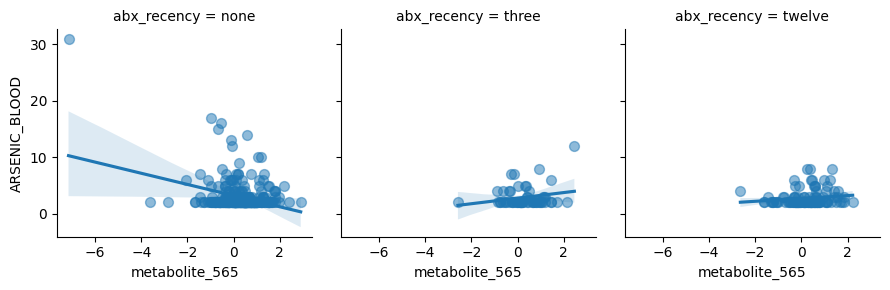

In [86]:
g = sns.FacetGrid(labs_mets, col="abx_recency")
g.map(sns.regplot, "metabolite_565", "ARSENIC_BLOOD", scatter_kws={'s': 50, 'alpha':0.5})

In [66]:
labs_mets[['ARSENIC_BLOOD','metabolite_565','abx_recency']].dropna()['abx_recency'].value_counts()

abx_recency
none      321
twelve    108
three      59
Name: count, dtype: int64

In [69]:
labs_mets[['ARSENIC_BLOOD','metabolite_565','abx_recency','vendor']].dropna()['vendor'].value_counts()

vendor
Quest    488
Name: count, dtype: int64

In [102]:
labs_mets[labs_mets['ARSENIC_BLOOD'] > 25]['ARSENIC_BLOOD']

1417    31.0
Name: ARSENIC_BLOOD, dtype: float64

In [ ]:
# 01773016

In [92]:
diet = pd.read_csv("../data/diet_collapsed.csv", dtype={'public_client_id':str})

In [99]:
as_out_diet = diet[diet['public_client_id'] == '01773016'].columns[diet[diet['public_client_id'] == '01773016'].columns.notna()]

In [101]:
diet[diet['public_client_id'] == '01773016'].dropna(axis=1) # No further info on the diet

,public_client_id,vendor,days_in_program,assessment:lifestyle:achohol_type:enum,assessment:lifestyle:alcohol_days_a_week:enum,assessment:lifestyle:breakfast:enum,assessment:lifestyle:cruciferous_vegetables:enum,assessment:lifestyle:snack:enum,assessment:lifestyle:fruits:enum,assessment:lifestyle:vegetables:enum,assessment:lifestyle:sugary_drinks:enum,assessment:lifestyle:water:enum,assessment:lifestyle:alcohol_drinks_a_day:enum,assessment:lifestyle:diet:enum,assessment:lifestyle:grains:enum,response_percentage
5585,01773016,Health 123,28.0,(0) No preference,(0) I do not drink,(0) Daily,(2) Once per week,(0) Daily,(1) 1,(2) 2-3,(1) 1,(2) 4-5 cups per day,(0) I do not drink,(8) Other,(1) 1-2,0.232143
